In [57]:
import numpy as np


In [59]:
from PIL import Image

In [61]:
import matplotlib.pyplot as plt

In [63]:
image = Image.open('cat_15.png')
np.array(image).shape

(600, 337, 3)

Image shape: (600, 337)


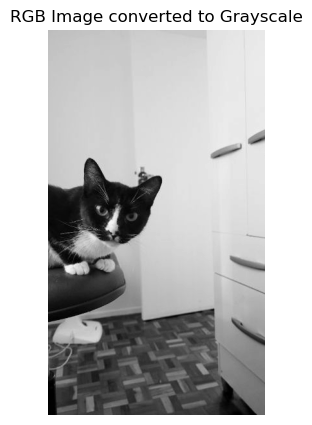

In [65]:
def img_transform(path):
    img = Image.open(path).convert('L')   
    w, h = img.size
    return np.asarray(img, dtype=np.float64)

IMAGE_PATH = 'cat_15.png'

A = img_transform(IMAGE_PATH)
m, n = A.shape
print('Image shape:', A.shape)

plt.figure(figsize=(5,5))
plt.imshow(A, cmap='gray')
plt.title('RGB Image converted to Grayscale')
plt.axis('off')
plt.show()

In [67]:
def find_ATA(A):
    #finding A^TA
    return A.T @ A


def matvec(A, v):
    #find U
    return np.array([np.sum(A[i, :] * v) for i in range(A.shape[0])])




In [69]:
def outer_prod(u, v):
    
    return u.reshape(-1, 1) * v.reshape(1, -1) # to reconstruct Ak, uvt


def frobenius_norm(M):
    #Frobenius norm to measure reconstruction error
    return np.sqrt(np.sum(np.abs(M) ** 2)) 

In [71]:
def creat_svd_via_eig(A):
    AtA = find_ATA(A)                          
    eigvals, V = np.linalg.eigh(AtA)      # find eigenvalues and eigenvectors

    n = len(eigvals)
    order = list(range(n))

    #  selection sort (descending) 
    for i in range(n):
        max_idx = i
        for j in range(i + 1, n):
            if eigvals[order[j]] > eigvals[order[max_idx]]:
                max_idx = j
        order[i], order[max_idx] = order[max_idx], order[i]

    #  reorder eigvals and V using the sorted order
    sorted_eigvals = np.zeros(n)
    sorted_V = np.zeros_like(V)
    for new_pos, old_idx in enumerate(order):
        val = eigvals[old_idx]
        sorted_eigvals[new_pos] = val if val > 0 else 0.0   # manual clip
        for row in range(V.shape[0]):
            sorted_V[row, new_pos] = V[row, old_idx]

    eigvals = sorted_eigvals
    V = sorted_V

    sing = np.sqrt(eigvals)               # built-in sqrt

    m, n_cols = A.shape
    r = sing.shape[0]
    U = np.zeros((m, r))

    # built-in vectorized computation for U
    AV = A @ V
    safe_sing = np.where(sing > 1e-10, sing, 1)
    U = np.where(sing > 1e-10, AV / safe_sing, 0.0)

    return U, sing, V

U, sing, V = creat_svd_via_eig(A)
print('U:', U.shape, ' singular values:', sing.shape, ' V:', V.shape)
print('Top 10 singular values:', np.round(sing[:10], 2))

U: (600, 337)  singular values: (337,)  V: (337, 337)
Top 10 singular values: [65332.76 12524.69  6390.68  5398.22  3736.68  3409.11  3012.    2807.98
  2262.    2187.06]


In [73]:
def reconstruct_svd(U, sing, V, k):
    """Ak = sum_{i=1}^{k} sigma_i * outer(U[:,i], V[:,i])"""
    m = U.shape[0]
    n = V.shape[0]
    Ak = np.zeros((m, n))
    for i in range(k):
        Ak += sing[i] * outer_prod(U[:, i], V[:, i])
    return Ak

k=20   Frobenius error E(k) = 3985.654
k=30   Frobenius error E(k) = 2966.320
k=80   Frobenius error E(k) = 1257.178


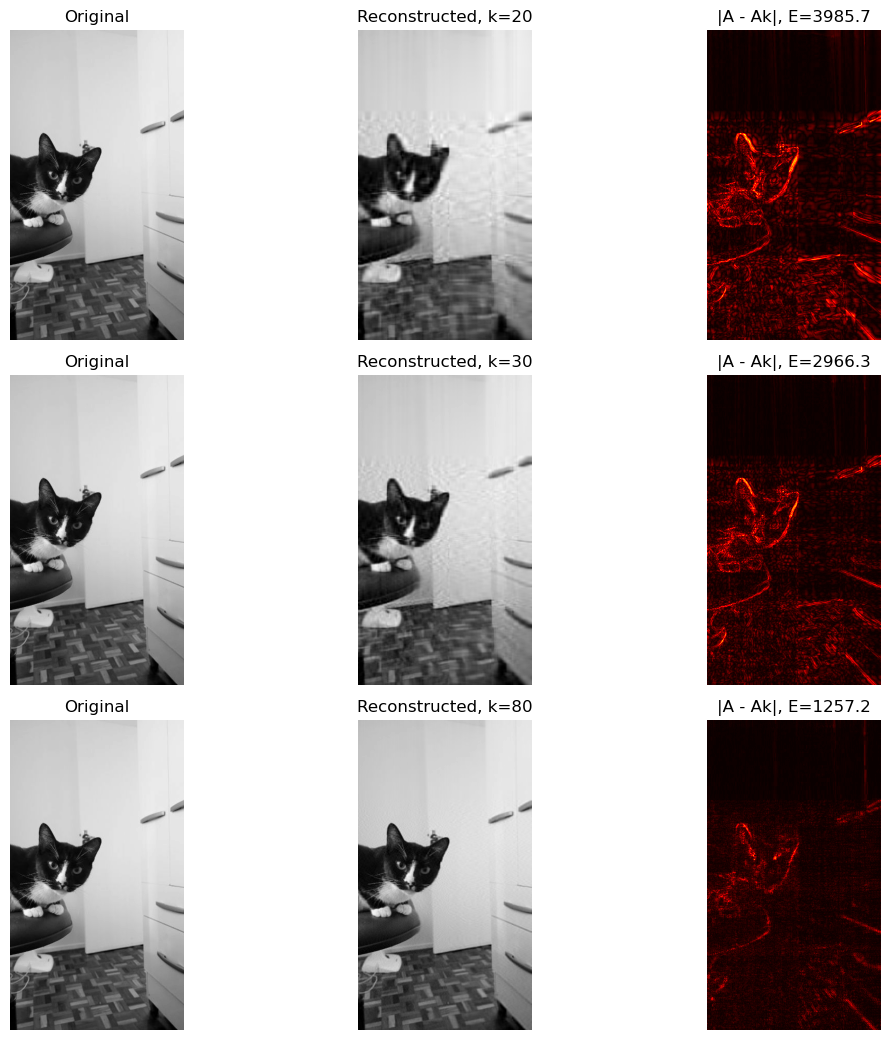

In [75]:
max_k = min(m, n)
k_values = (20, 30, 80)  
k_values = [min(k, max_k) for k in k_values]

fig, axes = plt.subplots(len(k_values), 3, figsize=(12, 3.5*len(k_values)))
for row, k in enumerate(k_values):
    Ak = reconstruct_svd(U, sing, V, k)
    err = np.abs(A - Ak)
    E = frobenius_norm(A - Ak)
    print(f'k={k}   Frobenius error E(k) = {E:.3f}')

    axes[row,0].imshow(A, cmap='gray');                    axes[row,0].set_title('Original')
    axes[row,1].imshow(np.clip(Ak,0,255), cmap='gray');     axes[row,1].set_title(f'Reconstructed, k={k}')
    axes[row,2].imshow(err, cmap='hot');                    axes[row,2].set_title(f'|A - Ak|, E={E:.1f}')
    for ax in axes[row]:
        ax.axis('off')

plt.tight_layout()
plt.show()

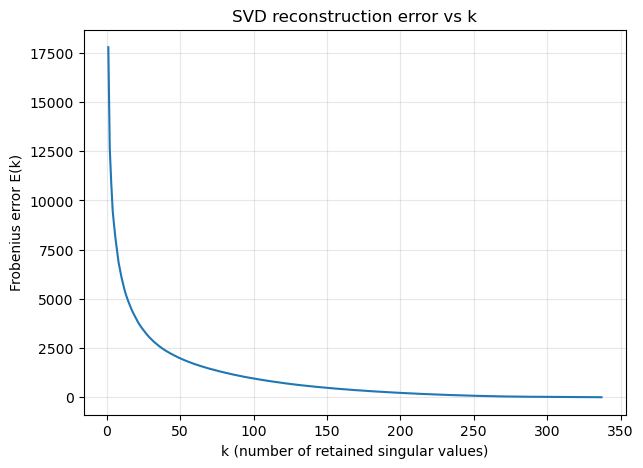

In [77]:
E_all = np.zeros(max_k)
Ak_running = np.zeros((m, n))
for i in range(max_k):
    Ak_running = Ak_running + sing[i] * outer_prod(U[:, i], V[:, i])
    E_all[i] = frobenius_norm(A - Ak_running)

plt.figure(figsize=(7,5))
plt.plot(np.arange(1, max_k+1), E_all)
plt.xlabel('k (number of retained singular values)')
plt.ylabel('Frobenius error E(k)')
plt.title('SVD reconstruction error vs k')
plt.grid(True, alpha=0.3)
plt.show()